## B4 · Adding and changing data

New columns, probability-style columns, method chaining and binning.

In [413]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

# The small table used in most examples on this sheet
df_students = pd.DataFrame({
    "name":   ["Ana", "Bo", "Cy", "Di"],
    "age":    [21, 25, 22, 30],
    "height": [165, 180, 172, 158],
}, index=["a1", "a2", "a3", "a4"])

### New columns

#### Adding a constant column

**B4.01**

`df['job'] = 'Student'`

Assigning a single value to a new column name allows us to add a column where every row has the same entry. It is useful for labelling rows before tables are combined. Alternatively, `df.assign(job="Student")` returns a new table with the column added.

In [414]:
# display the example data
df_students

,name,age,height
a1,Ana,21,165
a2,Bo,25,180
a3,Cy,22,172
a4,Di,30,158


In [415]:
df = df_students.copy()
df["job"] = "Student"       # every row receives the same value
df

,name,age,height,job
a1,Ana,21,165,Student
a2,Bo,25,180,Student
a3,Cy,22,172,Student
a4,Di,30,158,Student


`assign` does the same but returns a new table, leaving the original unchanged:

In [416]:
df_students.assign(job="Student")

,name,age,height,job
a1,Ana,21,165,Student
a2,Bo,25,180,Student
a3,Cy,22,172,Student
a4,Di,30,158,Student


In [417]:
df_students.columns.tolist()     # the original has no 'job' column

['name', 'age', 'height']

*See also:* Adding a calculated column (B4) · Stacking rows (B6) · Checking a DataFrame after each step (B1)

#### Adding a calculated column

**B4.02**

`df['new'] = df['col'] / n`

Assigning an expression to a new column name allows us to create a column from existing ones, calculated for every row at once. It is useful for unit conversions and derived variables. Alternatively, `df.assign(height_m=lambda d: d["height"] / 100)` does it inside a method chain.

In [418]:
# display the example data
df_students

,name,age,height
a1,Ana,21,165
a2,Bo,25,180
a3,Cy,22,172
a4,Di,30,158


In [419]:
df = df_students.copy()
df["height_m"] = df["height"] / 100
df["age_months"] = df["age"] * 12
df

,name,age,height,height_m,age_months
a1,Ana,21,165,1.65,252
a2,Bo,25,180,1.80,300
a3,Cy,22,172,1.72,264
a4,Di,30,158,1.58,360


*See also:* Adding a column from two columns (B4) · Adding a column with a NumPy function (B4) · Maths on a whole array (A4) · Checking a new column against a hand calculation (B1)

#### Adding a column from two columns

**B4.03**

`df['new'] = df['col_2'] - df['col_1']`

Doing arithmetic between two columns allows us to build a new column from both, row by row. It is useful for differences, ratios and totals. Alternatively, `df.diff(axis=1)` takes differences across neighbouring columns.

In [420]:
df_bp = pd.read_csv("data/bp_experiment2.csv")

In [421]:
# display example data
df_bp.head(3)

,id,gender,bp_day1,bp_day30
0,1,f,153.0,150.0
1,2,f,143.0,139.0
2,3,m,151.0,156.0


In [422]:
df_bp["change"] = df_bp["bp_day30"] - df_bp["bp_day1"]
df_bp["pct_change"] = (df_bp["change"] / df_bp["bp_day1"] * 100).round(1)
df_bp.head(3)

,id,gender,bp_day1,bp_day30,change,pct_change
0,1,f,153.0,150.0,-3.0,-2.0
1,2,f,143.0,139.0,-4.0,-2.8
2,3,m,151.0,156.0,5.0,3.3


*See also:* Adding a calculated column (B4) · Paired t-tests (D4) · Checking a new column against a hand calculation (B1)

#### Adding a column with a NumPy function

**B4.04**

`df['new'] = np.log10(df['col'])`

Passing a column to a NumPy function allows us to transform every value, for example by taking a logarithm. It is useful for log-transforming skewed data before analysis. Alternatively, pandas has some built-in methods such as `.abs()` and `.round()`.

In [423]:
# display the example data
df_students

,name,age,height
a1,Ana,21,165
a2,Bo,25,180
a3,Cy,22,172
a4,Di,30,158


In [424]:
df = df_students.copy()
df["log_age"] = np.log10(df["age"])
df["sqrt_age"] = np.sqrt(df["age"])
df.round(3)

,name,age,height,log_age,sqrt_age
a1,Ana,21,165,1.322,4.583
a2,Bo,25,180,1.398,5.000
a3,Cy,22,172,1.342,4.690
a4,Di,30,158,1.477,5.477


*See also:* Applying maths functions to an array (A4) · Log-log models (D5)

#### Changing values in a column

**B4.05**

`df.loc[mask, 'col'] = value`

The form `df.loc[mask, 'col'] = value` allows us to overwrite values only in the rows that meet a condition. It is useful for correcting errors or capping values. Alternatively, `np.where(cond, a, b)` builds a whole new column with two options.

In [425]:
# display the example data
df_students

,name,age,height
a1,Ana,21,165
a2,Bo,25,180
a3,Cy,22,172
a4,Di,30,158


In [426]:
df = df_students.copy()
df.loc[df["age"] > 24, "height"] = 0      # only the rows where age > 24 are changed
df

,name,age,height
a1,Ana,21,165
a2,Bo,25,0
a3,Cy,22,172
a4,Di,30,0


*See also:* Filtering rows and choosing columns (B3) · Adding a conditional column with `np.where` (B4) · Replacing and mapping values (B4)

### Probability-style columns

#### Turning counts into probabilities

**B4.06**

`df['prob'] = df['count'] / total`

If we have a column of counts out of a known total, then dividing by the total gives a column of probabilities. It is useful for turning enumerated outcomes into a probability distribution. Alternatively, `value_counts(normalize=True)` gives proportions directly.

All 6³ = 216 outcomes of rolling three dice are in a file; count how often each total occurs, then divide by 216.

In [427]:
df_combos = pd.read_csv("data/3_roll_combos.csv")

In [428]:
# display the example data
df_totals = df_combos["total"].value_counts().to_frame().sort_values(by="total")
df_totals.head()

,count
total,
3,1
4,3
5,6
6,10
7,15


In [429]:
df_totals["prob"] = df_totals["count"] / 216
df_totals.head()

,count,prob
total,,
3,1,0.004630
4,3,0.013889
5,6,0.027778
6,10,0.046296
7,15,0.069444


In [430]:
col_totals = df_combos["total"].value_counts()      # a Series of counts
df_totals = col_totals.to_frame()                   # a one-column DataFrame
df_totals = df_totals.sort_values(by="total")       # in order of the total
df_totals["prob"] = df_totals["count"] / 216
df_totals.head()

,count,prob
total,,
3,1,0.004630
4,3,0.013889
5,6,0.027778
6,10,0.046296
7,15,0.069444


*See also:* Counting each category (B5) · Building a frequency table (D1)

#### Calculating cumulative sums

**B4.07**

`df['new'] = df['col'].cumsum()`

The `.cumsum()` method allows us to calculate a running total down a column. It is useful for cumulative probabilities, P(X ≤ x). Alternatively, `np.cumsum()` does the same on an array.

In [431]:
df_combos = pd.read_csv("data/3_roll_combos.csv")      # every outcome of rolling three dice

In [432]:
df_totals = df_combos["total"].value_counts().to_frame().sort_values(by="total")
df_totals["prob"] = df_totals["count"] / 216
df_totals.head(4)                                   # before: counts and probabilities

,count,prob
total,,
3,1,0.004630
4,3,0.013889
5,6,0.027778
6,10,0.046296


In [433]:
df_totals["cum_prob"] = df_totals["prob"].cumsum()
df_totals.head(4)                                   # after: a running total is added

,count,prob,cum_prob
total,,,
3,1,0.004630,0.004630
4,3,0.013889,0.018519
5,6,0.027778,0.046296
6,10,0.046296,0.092593


In [434]:
round(df_totals["cum_prob"].iloc[-1], 6)            # the final value is 1.0

np.float64(1.0)

In [435]:
col_totals = df_combos["total"].value_counts()      # a Series of counts
df_totals = col_totals.to_frame()                   # a one-column DataFrame
df_totals = df_totals.sort_values(by="total")       # in order of the total
df_totals["prob"] = df_totals["count"] / 216
df_totals["cum_prob"] = df_totals["prob"].cumsum()
df_totals.head(4)

,count,prob,cum_prob
total,,,
3,1,0.004630,0.004630
4,3,0.013889,0.018519
5,6,0.027778,0.046296
6,10,0.046296,0.092593


*See also:* Rounding, accumulating and taking absolute values (A4) · Turning counts into probabilities (B4) · Adding a cumulative probability column (D1)

### Chains

#### Method chaining

**B4.08**

`df.method1().method2().method3()`

***(non-examinable)***

Method chaining allows us to apply several pandas methods in a row, each working on the result of the one before. It is useful because a cleaning recipe then reads top to bottom like a list of instructions, without many temporary variables. Alternatively, do one step per line and keep re-assigning the same variable; switch to *step by step* to see the equivalent.

Any method that returns a table (or Series) can be followed by a dot and another method. Read the chain left to right: "take the penguins, drop incomplete rows, put the heaviest first, keep the top three".

In [436]:
df_penguins.shape                                                  # the starting table: rows, columns

(344, 7)

In [437]:
df_penguins.dropna().sort_values("body_mass_g", ascending=False).head(3)     # three steps chained on one line

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
297,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male


In [438]:
df_output = df_penguins.dropna()                                          # step 1: drop rows with any missing value
df_output = df_output.sort_values("body_mass_g", ascending=False)         # step 2: heaviest first
df_output = df_output.head(3)                                             # step 3: keep the top three
df_output

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
297,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male


The number of rows shrinks as each step is applied:

In [439]:
print(f"{df_penguins.shape} -> {df_penguins.dropna().shape} -> {df_penguins.dropna().head(3).shape}")

(344, 7) -> (333, 7) -> (3, 7)


*See also:* Chaining methods on one line (B4) · Chaining methods over several lines (B4) · Checking a chain step by step (B4) · Avoiding `inplace=True` in a chain (B4)

#### Chaining methods on one line

**B4.09**

`s.value_counts().to_frame().sort_values(by=col)`

***(non-examinable)***

Method chaining allows us to apply several steps in a row, each working on the result of the previous one. It is useful for short sequences like count → table → sort. Alternatively, do one step per line and keep re-assigning the same variable, which lets each step be checked on its own.

In [440]:
df_combos = pd.read_csv("data/3_roll_combos.csv")

In [441]:
df_combos["total"].value_counts().to_frame().sort_values(by="total").head(3)

,count
total,
3,1
4,3
5,6


In [442]:
df_output = df_combos["total"].value_counts().to_frame()    # counts of each total, as a one-column table
df_output = df_output.sort_values(by="total")               # in order of the total
df_output = df_output.head(3)                               # the first three
df_output

,count
total,
3,1
4,3
5,6


*See also:* Chaining methods over several lines (B4) · Turning counts into a table (B5) · Sorting by a column (B3)

#### Chaining methods over several lines

**B4.10**

`( df.method().method() )`

***(non-examinable)***

Wrapping a chain in brackets allows us to write one step per line. It is useful for longer chains, because each step can be read and commented separately. Alternatively, do one step per line and keep re-assigning the same variable (step by step).

The spaces immediately inside the outer brackets `( … )` distinguish them from the brackets of each method.

In [443]:
df_output = ( df_penguins
              .dropna()                                       # remove incomplete rows
              .sort_values("body_mass_g", ascending=False)    # heaviest first
              .reset_index(drop=True)                         # renumber the rows 0, 1, 2 ...
              .head(3) )                                      # top 3
df_output

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
1,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
2,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male


In [444]:
df_output = df_penguins.dropna()                                  # remove incomplete rows
df_output = df_output.sort_values("body_mass_g", ascending=False) # heaviest first
df_output = df_output.reset_index(drop=True)                      # renumber the rows 0, 1, 2 ...
df_output = df_output.head(3)                                     # top 3
df_output

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
1,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
2,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male


*See also:* Chaining methods on one line (B4) · Removing rows with missing values (B5) · Sorting by a column (B3)

#### Checking a chain step by step

**B4.11**

`( df.step1().step2().step3() )`

***(non-examinable)***

Running a chain with its later steps left off allows us to see what each step produced, which is how to find the step where something goes wrong. It is useful whenever a long chain gives an unexpected result. Alternatively, write the chain as separate lines and display the variable after each one.

Build up the chain one step at a time and look at the result each time.

In [445]:
# display the example data
df_penguins.dropna().head(3)                                      # chain with step 1 only

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female


In [446]:
df_output = df_penguins.dropna()
df_output = df_output.head(3)
df_output

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female


In [447]:
( df_penguins
  .dropna()
  .sort_values("body_mass_g", ascending=False)
  .head(3) )                                                      # steps 1, 2 and 3

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
297,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male


In [448]:
df_output = df_penguins.dropna()
df_output = df_output.sort_values("body_mass_g", ascending=False)
df_output = df_output.head(3)
df_output

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
297,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male


In [449]:
( df_penguins
  .dropna()
  .sort_values("body_mass_g", ascending=False)
  .head(3)
  .reset_index(drop=True) )                                       # all four steps

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
1,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
2,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male


In [450]:
df_output = df_penguins.dropna()
df_output = df_output.sort_values("body_mass_g", ascending=False)
df_output = df_output.head(3)
df_output = df_output.reset_index(drop=True)
df_output

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
1,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
2,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male


*See also:* Method chaining (B4) · Chaining methods over several lines (B4) · Checking a DataFrame after each step (B1)

#### Avoiding `inplace=True` in a chain

**B4.12**

`df.dropna(inplace=True).head()`

***(non-examinable)***

A method called with `inplace=True` changes the table itself and returns `None`, so there is nothing left to chain onto. It is useful when a chain fails with a `'NoneType' object has no attribute` error, which this mistake causes. Alternatively, drop `inplace` and keep the returned table.

In [451]:
df = df_penguins.copy()
df.dropna(inplace=True).head()          # dropna changed df and returned None

AttributeError: 'NoneType' object has no attribute 'head'

Without `inplace`, each step hands its result to the next:

In [452]:
df_penguins.copy().dropna().head(3)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female


In [453]:
df_output = df_penguins.copy()
df_output = df_output.dropna()
df_output = df_output.head(3)
df_output

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female


*See also:* Method chaining (B4) · Keeping a result by reassigning or with `inplace` (B2) · Dropping rows by label (B2)

### Categories from numbers

#### Binning numbers into categories

**B4.13**

`pd.cut(df['col'], bins=edges, labels=names)`

The `pd.cut()` function allows us to sort a continuous column into labelled groups (bins). It is useful for turning a number into categories. Alternatively, `np.where` or `pd.qcut` (equal-sized groups) can also create categories.

`bins` gives the edges (each bin excludes its left edge and includes its right edge); `labels` names the bins.

In [454]:
# display the example data
df_students

,name,age,height
a1,Ana,21,165
a2,Bo,25,180
a3,Cy,22,172
a4,Di,30,158


In [455]:
df = df_students.copy()
df["height_group"] = pd.cut(df["height"], bins=[150, 165, 175, 190], labels=["short", "medium", "tall"])
df

,name,age,height,height_group
a1,Ana,21,165,short
a2,Bo,25,180,tall
a3,Cy,22,172,medium
a4,Di,30,158,short


In [456]:
df["height_group"].value_counts()

height_group
short     2
medium    1
tall      1
Name: count, dtype: int64

*See also:* Binning numbers into equal-sized groups with `qcut` (B4) · Adding a conditional column with `np.where` (B4) · Drawing a histogram (C2)

#### Comparing a variable across binned groups with a box plot

**B4.17**

`pd.cut(df['col'], bins=edges, labels=names); sns.boxplot(data=df, x='group', y='col')`

***(non-examinable)***

If a numeric variable has been cut into labelled bins, then a box plot of a second variable for each bin shows how the second variable changes across the range of the first. It is useful for judging whether a relationship is steady, curved or changing in spread without assuming a straight line. Alternatively, a scatter plot shows every point, and `groupby` on the bins gives the numbers behind the boxes.

Two numeric columns are used: flipper length (to be cut into groups) and body mass (to be compared across the groups).

In [457]:
df_binned = df_penguins.dropna(subset=["flipper_length_mm", "body_mass_g"]).copy()
df_binned[["flipper_length_mm", "body_mass_g"]].head()

,flipper_length_mm,body_mass_g
0,181.0,3750.0
1,186.0,3800.0
2,195.0,3250.0
4,193.0,3450.0
5,190.0,3650.0


`pd.cut` gives each row the label of the bin its flipper length falls in:

In [458]:
df_binned["flipper_group"] = pd.cut(df_binned["flipper_length_mm"],
                                    bins=[170, 185, 200, 215, 235],
                                    labels=["170-185", "185-200", "200-215", "215-235"])
df_binned[["flipper_length_mm", "flipper_group"]].head()

,flipper_length_mm,flipper_group
0,181.0,170-185
1,186.0,185-200
2,195.0,185-200
4,193.0,185-200
5,190.0,185-200


In [459]:
df_binned["flipper_group"].value_counts().sort_index()      # penguins in each bin

flipper_group
170-185     41
185-200    153
200-215     81
215-235     67
Name: count, dtype: int64

One box per bin shows how body mass changes as flipper length increases:

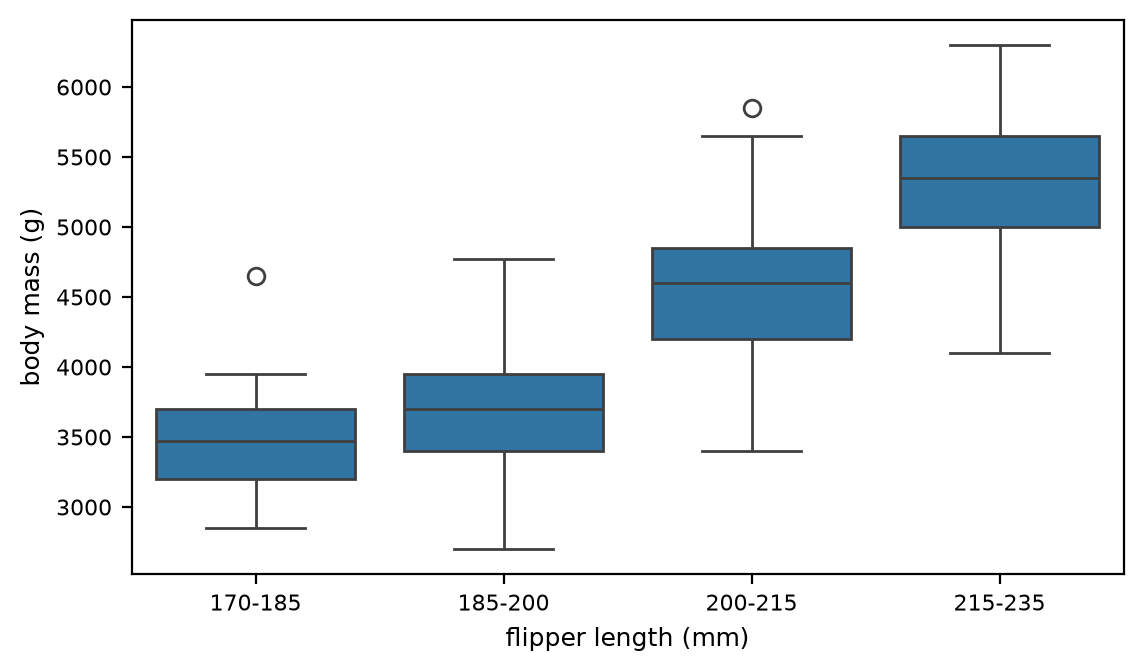

In [460]:
sns.boxplot(data=df_binned, x="flipper_group", y="body_mass_g")
plt.xlabel("flipper length (mm)")
plt.ylabel("body mass (g)");

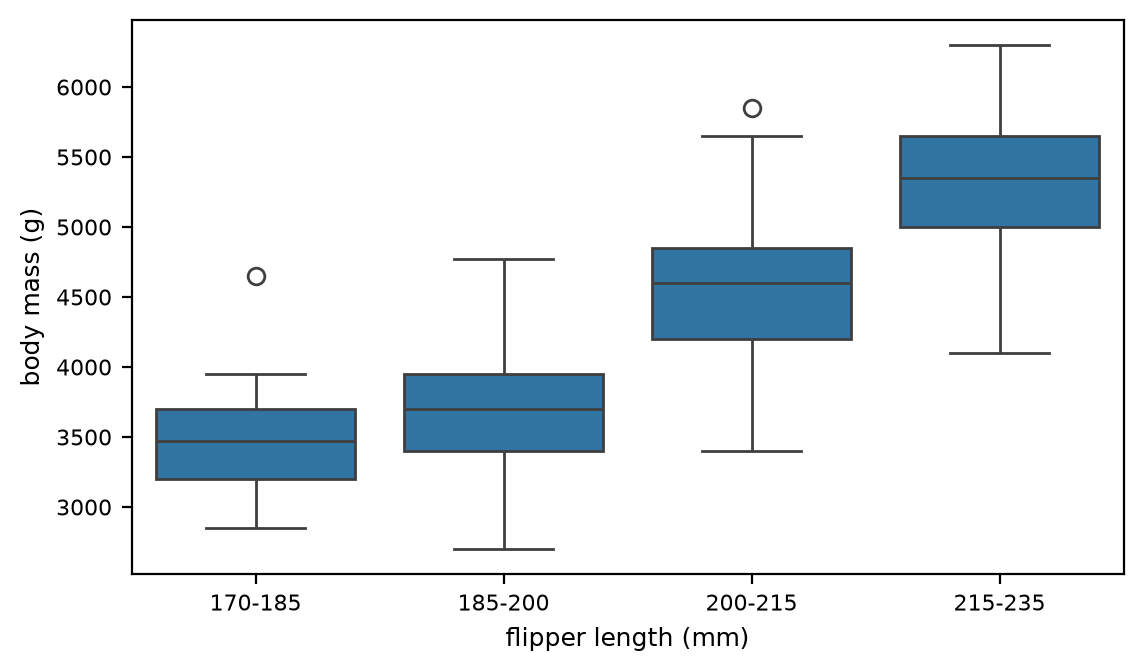

In [461]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
sns.boxplot(data=df_binned, x="flipper_group", y="body_mass_g", ax=ax)
ax.set_xlabel("flipper length (mm)")
ax.set_ylabel("body mass (g)");

Watch out: each bin includes its right edge but not its left edge, so `(170, 185]`. A value outside every bin becomes `NaN` and is left out of the plot.

*See also:* Binning numbers into categories (B4) · Drawing a box plot with `boxplot` (C3) · Drawing a scatter plot with `scatterplot` (C3) · Calculating several statistics per group (B9) · Binning numbers into equal-sized groups with `qcut` (B4)

#### Binning numbers into equal-sized groups with `qcut`

**B4.18**

`pd.qcut(df['col'], q=n, labels=names)`

***(non-examinable)***

The `pd.qcut()` function allows us to cut a column into groups that each hold about the same number of rows, such as quartiles. It is useful when the spread of the values is uneven, so that fixed-width bins would leave some groups almost empty. Alternatively, `pd.cut` makes bins of chosen width, which is better when the edges have a meaning.

In [462]:
df_q = df_penguins.dropna(subset=["body_mass_g"]).copy()
df_q["body_mass_g"].head()

0    3750.0
1    3800.0
2    3250.0
4    3450.0
5    3650.0
Name: body_mass_g, dtype: float64

In [463]:
df_q["mass_group"] = pd.qcut(df_q["body_mass_g"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])
df_q[["body_mass_g", "mass_group"]].head()

,body_mass_g,mass_group
0,3750.0,Q2
1,3800.0,Q2
2,3250.0,Q1
4,3450.0,Q1
5,3650.0,Q2


Each group holds about a quarter of the penguins:

In [464]:
df_q["mass_group"].value_counts().sort_index()

mass_group
Q1    89
Q2    87
Q3    81
Q4    85
Name: count, dtype: int64

The cut points can be returned with `retbins=True`:

In [465]:
pd.qcut(df_q["body_mass_g"], q=4, retbins=True)[1]

array([2700., 3550., 4050., 4750., 6300.])

*See also:* Binning numbers into categories (B4) · Finding quartiles (B5) · Comparing a variable across binned groups with a box plot (B4)

### Recoding and tidying values

#### Replacing and mapping values

**B4.14**

`s.replace(d), s.map(d)`

***(non-examinable)***

The `.replace()` and `.map()` methods allow us to recode values using a dictionary. They are useful for turning codes into readable labels. Alternatively, `np.where` handles a simple two-way choice.

Adelie, Chinstrap and Gentoo are the three penguin species in this dataset.
`replace` leaves unmatched values alone; `map` turns unmatched values into `NaN`.

In [466]:
# display the example data
s = pd.Series(["A", "G", "X"])
s

0    A
1    G
2    X
dtype: object

In [467]:
print(f"replace: {s.replace({'A': 'Adelie', 'G': 'Gentoo'}).tolist()}")

replace: ['Adelie', 'Gentoo', 'X']


In [468]:
print(f"map    : {s.map({'A': 'Adelie', 'G': 'Gentoo'}).tolist()}")

map    : ['Adelie', 'Gentoo', nan]


*See also:* Recoding values with a dictionary (A3) · Adding a conditional column with `np.where` (B4) · Changing values in a column (B4)

#### Adding a conditional column with `np.where`

**B4.15**

`np.where(cond, a, b)`

***(non-examinable)***

The `np.where(condition, a, b)` function allows us to fill a new column with `a` where a condition is true and `b` elsewhere. It is useful for flags that depend on a condition. Alternatively, `pd.cut` handles more than two groups.

`np.where(condition, a, b)` gives `a` where the condition is true and `b` elsewhere.

In [469]:
# display the example data
df_students

,name,age,height
a1,Ana,21,165
a2,Bo,25,180
a3,Cy,22,172
a4,Di,30,158


In [470]:
df = df_students.copy()
df["tall"] = np.where(df["height"] > 170, "yes", "no")
df

,name,age,height,tall
a1,Ana,21,165,no
a2,Bo,25,180,yes
a3,Cy,22,172,yes
a4,Di,30,158,no


*See also:* Binning numbers into categories (B4) · Changing values in a column (B4) · Clipping and rounding values (B4)

#### Clipping and rounding values

**B4.16**

`s.clip(lower, upper), s.round(n), df.round(n)`

***(non-examinable)***

The `.clip()` and `.round()` methods allow us to limit values to a range and tidy decimals. They are useful for capping outliers and neat output. Alternatively, `.loc[mask, 'col'] = value` caps values by condition.

In [471]:
# display the example data
s = pd.Series([1.234, 5.678, 9.1011])
s

0    1.2340
1    5.6780
2    9.1011
dtype: float64

In [472]:
s.clip(2, 8).tolist()       # values forced into the range 2 to 8

[2.0, 5.678, 8.0]

In [473]:
s.round(1).tolist()

[1.2, 5.7, 9.1]

*See also:* Rounding a number (A1) · Changing values in a column (B4) · Adding a calculated column (B4)